Dorothee MG

Study: Validation of empathy videos\
    Step 1: Targets are filmed talking about emotional life events\
    Step 2: Targets watch their own videos and rate the emotional valence they felt during recording + identify the specific emotions they felt\
    Step 3: Perceivers watch targets' videos and rate them (same scales)
      
Here we use data from the continuous evaluation of the target's emotional state, by targets and perceivers. Evaluation is logged every .5s 

Goal: Prepare 'smoothed' data for both targets and perceivers (with different methods of smoothing)\
      Graph data



In [1]:

# libraries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d


Prepare lists of targets and perceivers and load data

In [ ]:
# lists of participants

targets = ["P03_joy", "P29_joy", "P34_joy", "P42_joy", "P44_joy",
           "P12_sadness", "P15_sadness", "P27_sadness", "P34_sadness", "P44_sadness",
           "P03_anger", "P15_anger", "P22_anger", "P38_anger", "P42_anger", 
           "P17_pride", "P22_pride", "P29_pride", "P42_pride", "P44_pride",
           "P03_shame", "P22_shame", "P37_shame", "P38_shame", "P45_shame",
           "P12_neutral", "P17_neutral", "P29_neutral", "P34_neutral", "P38_neutral"]

perceivers = ["S01", "S02", "S03", "S04", "S05", "S06", "S07", "S08", "S11", "S15", "S18", "S20", "S23",
                "S24", "S28", "S34", "S37", "S42", "S44", "S45", "S47", "S49", "S51", "S54", "S55", "S57", "S64", "S65"]

# load data

target_data = pd.read_csv("behavioral_data/TARGET_video_ratings_continuous.csv")

perceiver_data = pd.read_csv("behavioral_data/PERCEIVER_video_ratings_continuous.csv")

In [ ]:
# This will help later to get the emotion from the target:
target_emotion = lambda x : x.split("_")[1]

In [ ]:
# This will help for plotting later
emotion_colour = {'anger':'red','shame':'green','neutral':'darkgray','sadness':'blue','pride':'purple','joy':'orange'}

In [ ]:
# Determine the maximum time of any video
video_dur = {}
for target in targets:
    dat = target_data[target]
    last_valid = np.max(np.where(~pd.isna(dat))) # find the maximum time index with non-NA data
    video_dur[target]= target_data['time'][last_valid]
MAX_T = max(video_dur.values()) # find the longest video duration

Make a function to smooth data in rolling window of 10s. 

method #1: 'mean'. For each datapoint, take the mean of all datapoints within +/- 5s. \
method #2: 'gaussian'. ≈ +/- 5s window with more weight on closer datapoints. 


In [ ]:

WINDOW_SIZE = 10 # half-window (10 datapoints = 5s)

def mean_sliding_window(values, window_size=WINDOW_SIZE): # values = target or perceiver data
    
    mean_smoothed_values = np.full(len(values), np.nan)  # store values (begin with NaNs)
    last_valid_data = values.last_valid_index()  # find the last datapoint (which is different for each target due to different video duration)
    
    for i in range(last_valid_data + 1):  # loop through every datapoint but stop smoothed values at last valid index (so the window doesn't go out of range)
                                          # +1 otherwise it stops before the last datapoint
        start_index = max(0, i - window_size)  # ensures start doesn't go negative
        end_index = min(last_valid_data, i + window_size + 1) # ensures end doesn't exceed data (+1 to include last datapoint)
        
        window_values = values[start_index:end_index]  
        mean_smoothed_values[i] = np.nanmean(window_values)  # place mean value (ignore nans)
    
    return mean_smoothed_values  # new smoothed values





def gaussian_sliding_window(values, sigma=3.5): # sigma = sd 
                                                # about 99.7% of weight is between 3 sd, so here window is about +/- 10.5 datapoints (5.25s)
    
    gaussian_smoothed_values = np.full(len(values), np.nan)  # store values (begin with nans)
    last_valid_data = values.last_valid_index()  # find the last datapoint

    smoothed_values = gaussian_filter1d(values[:last_valid_data + 1], sigma=sigma, mode='nearest') # apply smoothing

    gaussian_smoothed_values[:last_valid_data + 1] = smoothed_values  # store valid data

    return gaussian_smoothed_values # new smoothed values


Apply both smoothing methods and save in csv

In [7]:

# 'smoothed' data in csv for both targets and perceivers
mean_smoothed_target_data = {"time": target_data["time"].tolist()}  # start with time column
mean_smoothed_perceiver_data = {"time": perceiver_data["time"].tolist()} 
gaussian_smoothed_target_data = {"time": target_data["time"].tolist()}  
gaussian_smoothed_perceiver_data = {"time": perceiver_data["time"].tolist()} 

for target in targets:
    mean_smoothed_target_data[target] = mean_sliding_window(target_data[target])
    gaussian_smoothed_target_data[target] = gaussian_sliding_window(target_data[target])

for perceiver in perceivers:
    for target in targets:
        perceiver_col = f"{perceiver}_{target}"
        if perceiver_col not in perceiver_data.columns:
            continue # perceivers did not watch all targets
        mean_smoothed_perceiver_data[perceiver_col] = mean_sliding_window(perceiver_data[perceiver_col])
        gaussian_smoothed_perceiver_data[perceiver_col] = gaussian_sliding_window(perceiver_data[perceiver_col])

mean_smoothed_target = pd.DataFrame(mean_smoothed_target_data)
mean_smoothed_target.to_csv("outputs/mean_smoothed_target.csv", index=False) # index = row nbs
mean_smoothed_perceiver = pd.DataFrame(mean_smoothed_perceiver_data)
mean_smoothed_perceiver.to_csv("outputs/mean_smoothed_perceiver.csv", index=False)

gaussian_smoothed_target = pd.DataFrame(gaussian_smoothed_target_data)
gaussian_smoothed_target.to_csv("outputs/gaussian_smoothed_target.csv", index=False)
gaussian_smoothed_perceiver = pd.DataFrame(gaussian_smoothed_perceiver_data)
gaussian_smoothed_perceiver.to_csv("outputs/gaussian_smoothed_perceiver.csv", index=False)


graph of original data, and smoothed data with both methods

In [ ]:
# big graphs to see details

for target in targets: # plot target (original and both smoothed methods)
    
    plt.figure(figsize=(15,5))
        
    plt.plot(target_data['time'], target_data[target], color='black', label='original') 
    plt.plot(mean_smoothed_target['time'], mean_smoothed_target[target], color='red', label='mean_smooth')
    plt.plot(gaussian_smoothed_target['time'], gaussian_smoothed_target[target], color='blue', label='gauss_smooth')
    
    plt.ylim(0,10)
    plt.title(f'{target}')
    plt.xlabel('time (s)')
    plt.ylabel('rating')
    plt.legend()
    plt.show()

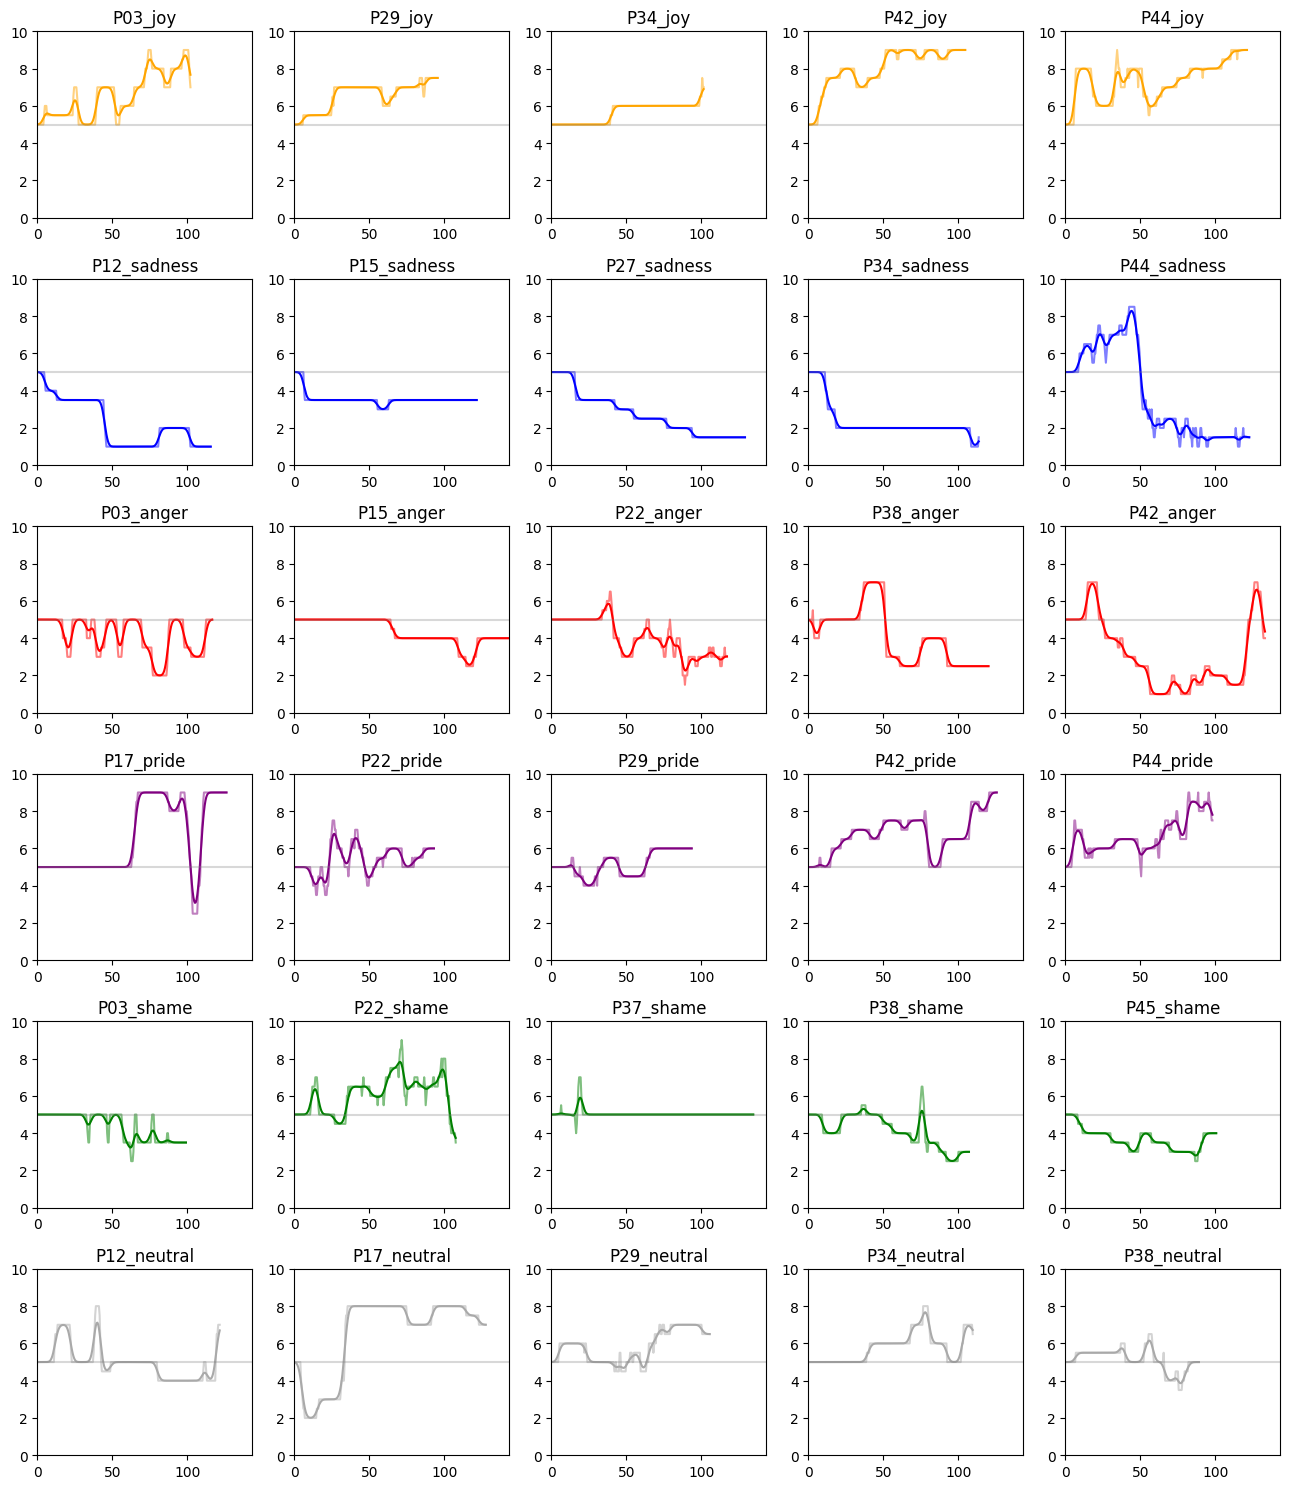

In [ ]:
# plot overview of all targets

nrow = 6 # how many rows you want
ncol = 5 # how many colums you want
fig, axs = plt.subplots(nrow, ncol, figsize=(13,15))
for i, ax in enumerate(fig.axes):
    target = targets[i]
    emotion = target_emotion(target)
    colour = emotion_colour[emotion]
    ax.plot(target_data['time'], target_data[target], color=colour, alpha=.5)
    ax.plot(gaussian_smoothed_target['time'], gaussian_smoothed_target[target], color=colour, label='target') 
    # standardize the axes so we can actually compare videos visually more easily:
    ax.set_xlim(0,MAX_T)
    ax.set_ylim(0,10) 
    ax.axhline(y=5,color='gray',alpha=.3) # add a little reference line so we know what is neutral
    ax.set_title(target)
        
plt.tight_layout() # make the layout a bit tighter: eliminate unnecessary whitespace    


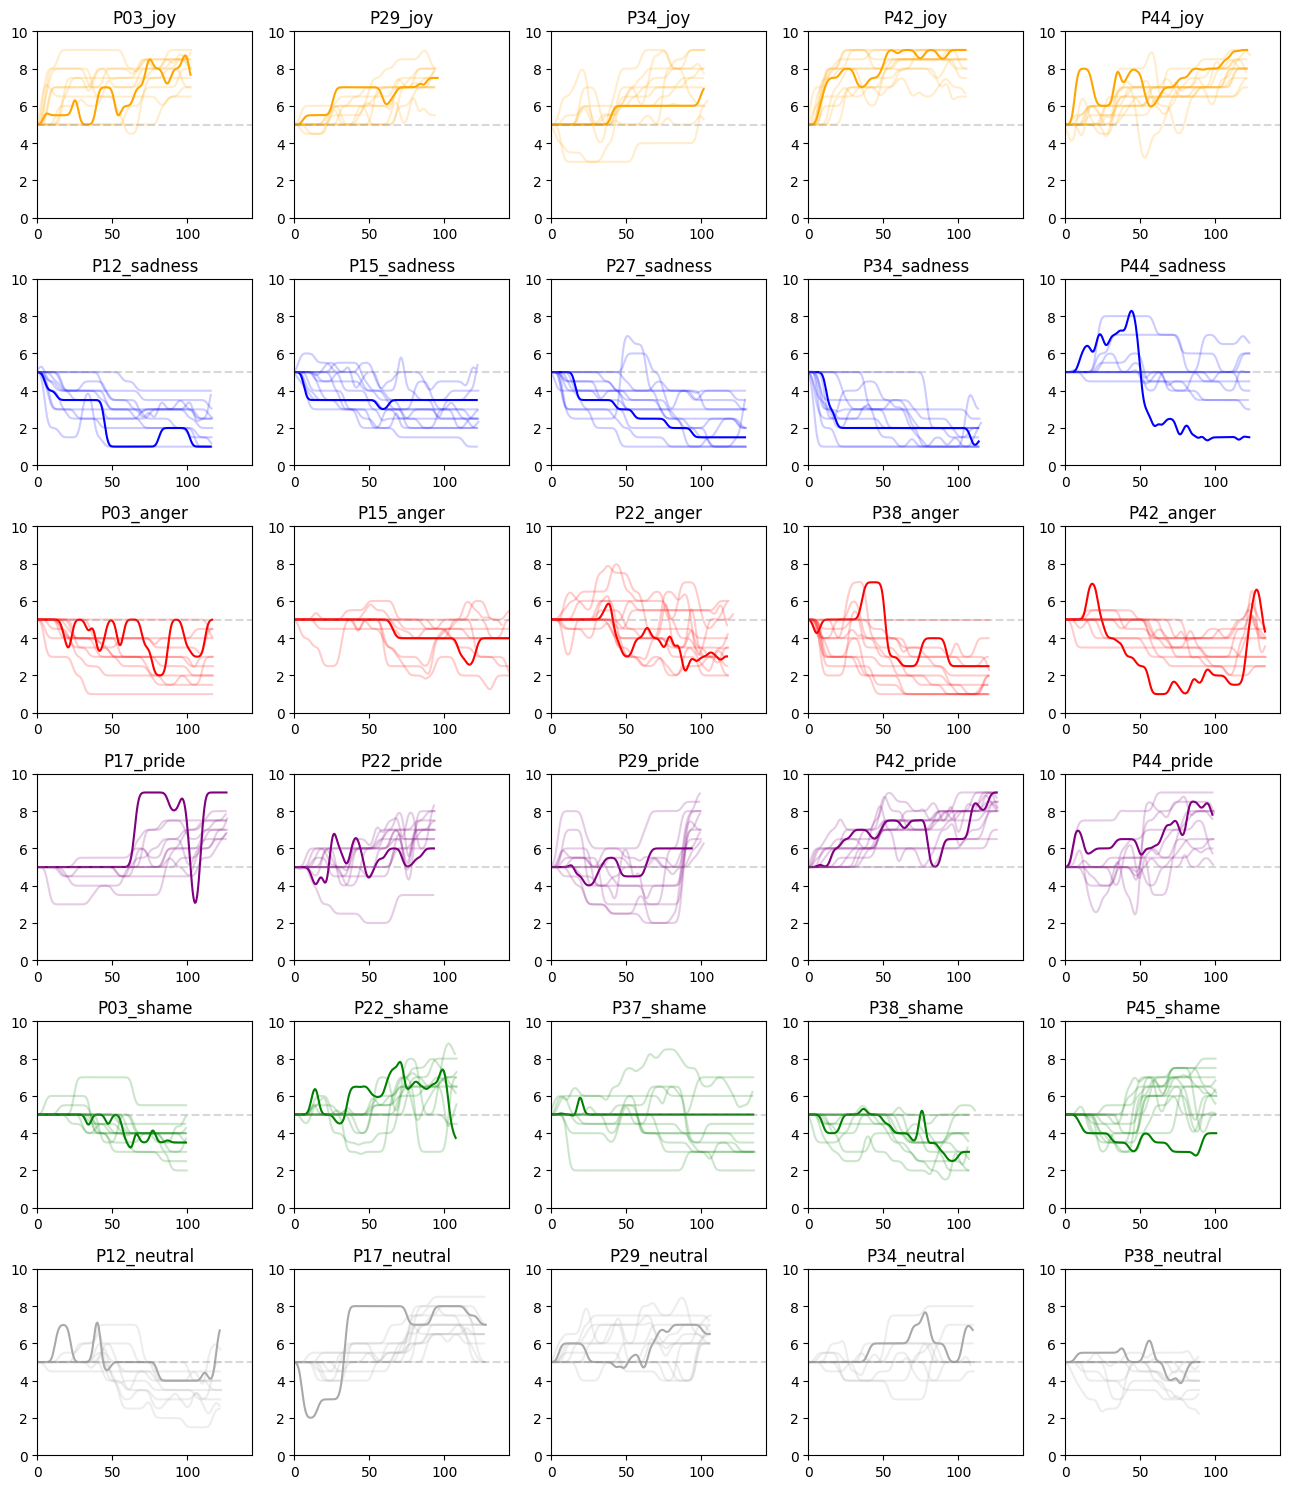

In [ ]:
# adding the perceiver traces

nrow = 6 
ncol = 5 
fig, axs = plt.subplots(nrow, ncol, figsize=(13,15))
for i, ax in enumerate(fig.axes):
    target = targets[i]
    emotion = target_emotion(target)
    colour = emotion_colour[emotion]
    
    for perceiver in perceivers: # plot perceivers
        if f'{perceiver}_{target}' not in perceiver_data.columns:
            continue # perceivers did not watch all targets
        ax.plot(gaussian_smoothed_perceiver['time'], gaussian_smoothed_perceiver[f'{perceiver}_{target}'], color=colour, alpha=.2)
        
    ax.plot(gaussian_smoothed_target['time'], gaussian_smoothed_target[target], color=colour, label='target') 
    
    ax.set_xlim(0,MAX_T) # x is the same for all targets
    ax.set_ylim(0,10) # y from 0 to 10 
    ax.axhline(y=5,color='gray',alpha=.3, linestyle = '--') # neutral line
    ax.set_title(target)
        
plt.tight_layout() 




graph of smoothed (method: gaussian) data for each target and its perceivers

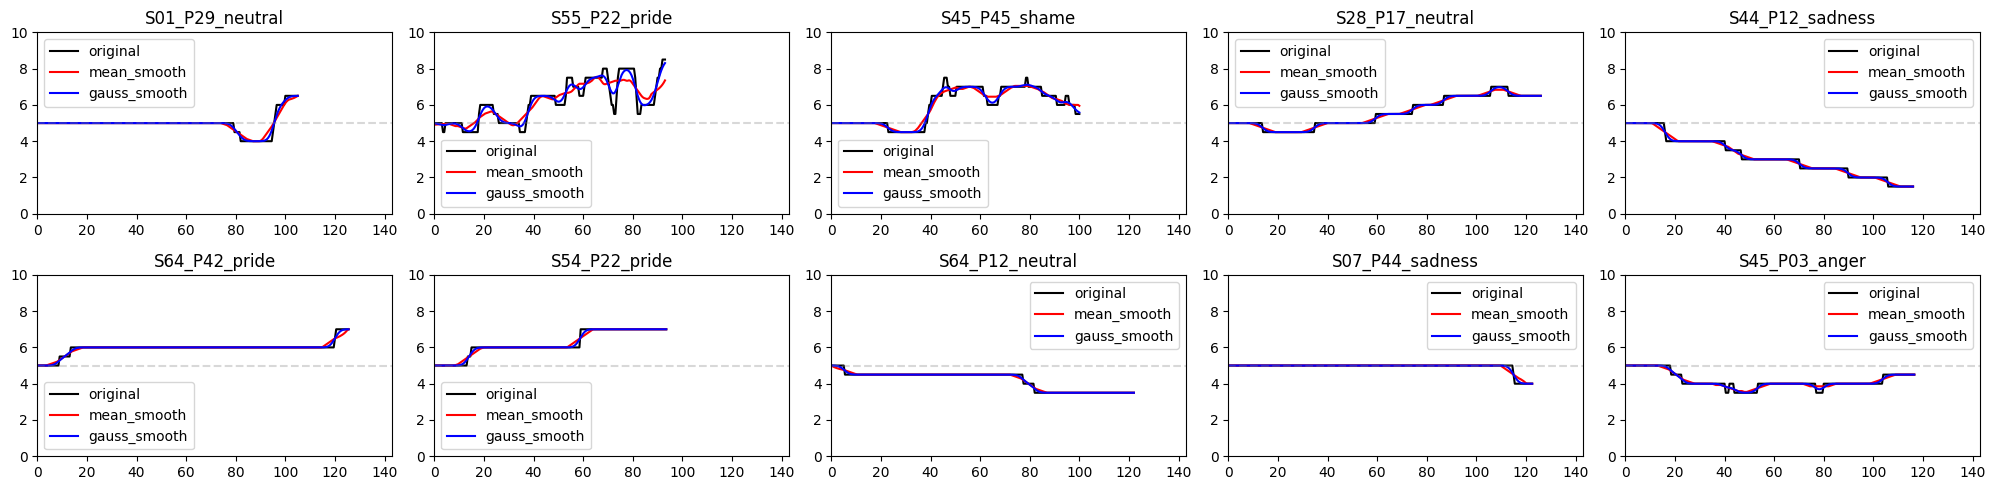

In [ ]:
# plot 10 random perceiver evaluations to check for anomalies.
# gaussian smoothing seems more accurate.

import random

perceiver_columns = [column for column in perceiver_data.columns if '_' in column] # just in case the column is 'time'
random_columns = random.sample(perceiver_columns, 10) # select 10 random columns

fig, axs = plt.subplots(2, 5, figsize=(20, 5)) # 2 rows of 5 columns

for i, ax in enumerate(fig.axes):
    column = random_columns[i]
    ax.plot(perceiver_data['time'], perceiver_data[column], color='black', label='original')
    ax.plot(mean_smoothed_perceiver['time'], mean_smoothed_perceiver[column], color='red', label='mean_smooth')
    ax.plot(gaussian_smoothed_perceiver['time'], gaussian_smoothed_perceiver[column], color='blue', label='gauss_smooth')
    
    ax.set_xlim(0, MAX_T)
    ax.set_ylim(0, 10)
    ax.axhline(y=5, color='gray', alpha=.3, linestyle='--')
    ax.set_title(column)
    ax.legend()

plt.tight_layout()




In [ ]:
for target in targets: # plot target and perceivers (smoothed)
    
    plt.figure(figsize=(15,5))
        
    for perceiver in perceivers: 
        perceiver_col = f"{perceiver}_{target}"
        if perceiver_col not in perceiver_data.columns:
            continue
        plt.plot(gaussian_smoothed_perceiver['time'], gaussian_smoothed_perceiver[perceiver_col], color='darkblue') # smoothed perceiver
        
    plt.plot(gaussian_smoothed_target["time"], gaussian_smoothed_target[target], label="target", color='red', linewidth=2) # smoothed target
    plt.ylim(0,10)
    plt.title(f'{target}')
    plt.xlabel('time (s)')
    plt.ylabel('rating')
    plt.show()